# 05 · Sales and profitability analysis
Business questions 1–13. The SQL results (`reports/sql_outputs`) are the source of truth; pandas is used for charts and statistical tests.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # project root, so `src` is importable
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
engine = get_engine()
from scipy import stats

## 1. Headline KPIs (Q1)

In [2]:
an.sql_output('q01_headline_kpis').T.rename(columns={0: 'value'})

,value
gross_sales_kes,"494,333,019.00"
discounts_kes,"4,694,604.00"
net_revenue_kes,"489,638,415.00"
cogs_kes,"398,445,692.00"
gross_profit_kes,"91,192,723.00"
gross_margin_pct,18.62
discount_rate_pct,0.95
units_sold,"2,219,840.00"
transactions,"289,936.00"
avg_transaction_value_kes,"1,688.78"


## 2. Growth: headline vs like-for-like (Q2)

In [3]:
an.sql_output('q03_year_over_year')

,scope,year1_revenue_kes,year2_revenue_kes,revenue_growth_pct,gross_profit_growth_pct
0,Like-for-like (excl. BR10),"228,952,204.00","243,370,121.00",6.30,5.96
1,All branches,"232,782,638.00","256,855,777.00",10.34,9.96


Part of the headline growth is simply Ruiru opening. Like-for-like growth is the honest measure of how the existing estate performed.

## 3. Branches and counties (Q3, Q4, Q11)

,county,branches,revenue_kes,share_pct,revenue_per_branch_kes,gross_margin_pct
0,Nairobi,3,"148,017,135.00",30.23,"49,339,045.00",18.75
1,Mombasa,2,"109,443,456.00",22.35,"54,721,728.00",17.92
2,Nakuru,2,"82,621,239.00",16.87,"41,310,619.00",18.69
3,Kiambu,2,"58,493,282.00",11.95,"29,246,641.00",18.68
4,Kisumu,1,"37,519,873.00",7.66,"37,519,873.00",19.17
5,Uasin Gishu,1,"36,156,495.00",7.38,"36,156,495.00",19.09
6,Machakos,1,"17,386,934.00",3.55,"17,386,934.00",19.35


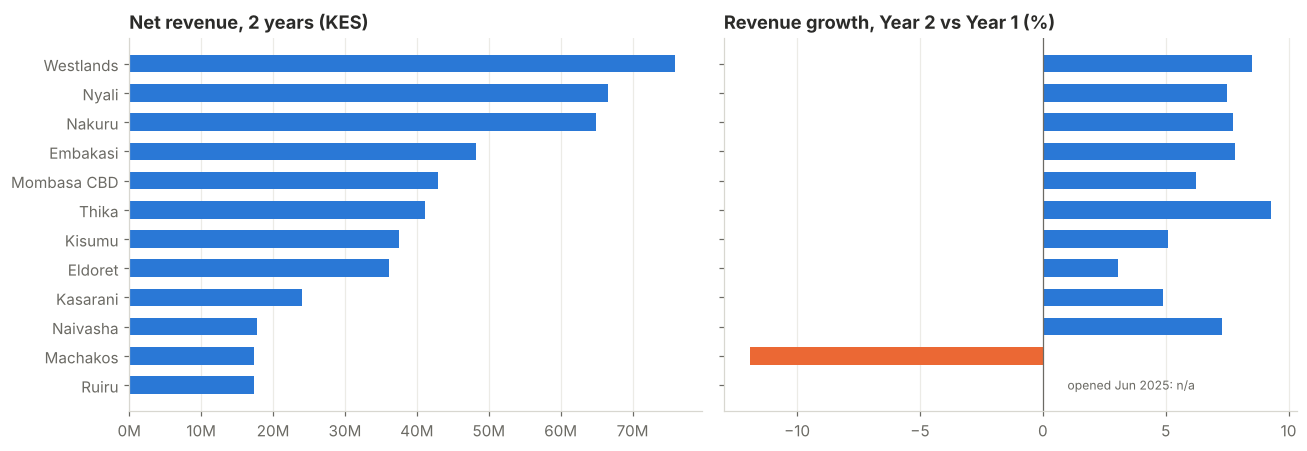

In [4]:
b = an.sql_output("q04_branch_ranking")
g = an.sql_output("q11_branch_growth_trend")[["branch_id", "yoy_growth_pct"]]
b = b.merge(g, on="branch_id")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
order = b.sort_values("revenue_kes").branch_name.str.replace("Savanna Fresh ", "")
bb = b.set_index(b.branch_name.str.replace("Savanna Fresh ", "")).loc[order]
axes[0].barh(order, bb.revenue_kes, color=an.PRIMARY, height=.6); an.kes_axis(axes[0], "x"); axes[0].set_title("Net revenue, 2 years (KES)")
cols = [an.HIGHLIGHT if v < 0 else an.PRIMARY for v in bb.yoy_growth_pct.fillna(0)]
axes[1].barh(order, bb.yoy_growth_pct.fillna(0), color=cols, height=.6); axes[1].axvline(0, color=an.INK_MUTED, lw=.8)
axes[1].set_title("Revenue growth, Year 2 vs Year 1 (%)")
axes[1].text(1, list(order).index("Ruiru"), "opened Jun 2025: n/a", va="center", fontsize=8, color=an.INK_MUTED)
for a in axes: a.grid(axis="y", visible=False)
fig.tight_layout(); an.save(fig, "branch_revenue_growth");
an.sql_output("q05_county_contribution")

Machakos (BR12) is the only established branch with falling sales, and its latest quarter is worse than its annual decline. Mombasa has the highest revenue per branch, but also the lowest county margin, which points to Nyali (next section).

## 4. Categories: revenue share vs profit share (Q5, Q13)

,category,gross_margin_pct,revenue_share_pct,gp_share_pct,lfl_revenue_growth_pct,lfl_gp_growth_pct
0,Household & Cleaning,24.47,10.89,14.31,-2.85,-2.64
1,Snacks & Confectionery,28.19,2.85,4.31,1.65,3.67
2,Dairy,15.39,14.70,12.15,7.51,5.28
3,Personal Care,31.29,3.57,5.99,6.46,5.92
4,Bakery,25.16,3.69,4.98,9.18,7.71
5,Meat & Poultry,18.55,6.73,6.70,7.97,7.90
6,Beverages,22.31,12.36,14.81,7.06,8.08
7,Baby Care,19.69,6.82,7.21,8.42,8.12
8,Fresh Produce,33.12,7.28,12.95,8.24,8.24
9,Staples,9.93,31.12,16.59,7.60,9.05


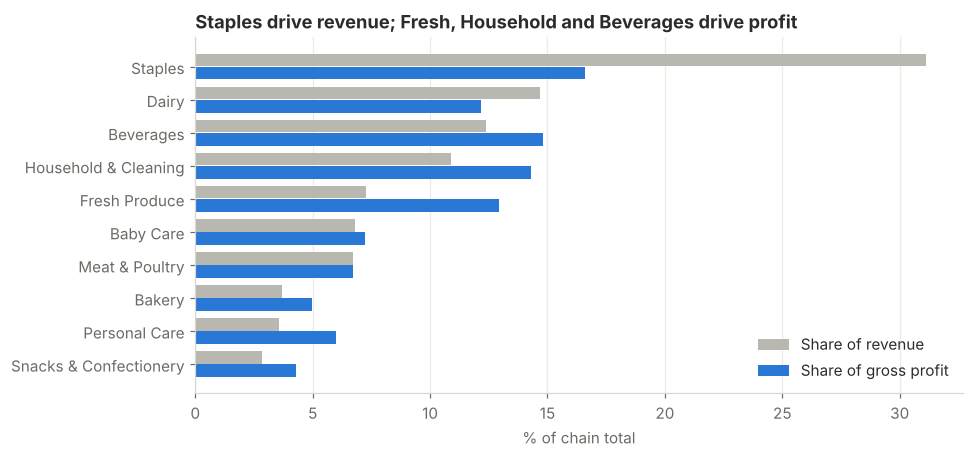

In [5]:
c = an.sql_output("q15_category_performance").sort_values("revenue_share_pct")
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(c))
ax.barh(y + .2, c.revenue_share_pct, height=.38, color=an.CONTEXT, label="Share of revenue")
ax.barh(y - .2, c.gp_share_pct, height=.38, color=an.PRIMARY, label="Share of gross profit")
ax.set_yticks(y, c.category); ax.set_xlabel("% of chain total"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Staples drive revenue; Fresh, Household and Beverages drive profit")
an.save(fig, "category_revenue_vs_profit_share");
c.sort_values("lfl_gp_growth_pct")[["category", "gross_margin_pct", "revenue_share_pct", "gp_share_pct", "lfl_revenue_growth_pct", "lfl_gp_growth_pct"]]

**Underperforming categories**
- **Household & Cleaning** is the only category whose like-for-like revenue *and* gross profit fell year-on-year, although it is the third-largest profit contributor. Notebook 06 links this to two SKUs whose sales collapsed while stock kept arriving.
- **Snacks & Confectionery** grew far below the chain average.
- **Staples** are 31% of revenue but only about 17% of gross profit at a 9.9% margin. This is a traffic-driver category, not a problem in itself, but it is where every point of discount hurts most.

## 5. High revenue, low margin products (Q9, Q10)

In [6]:
an.sql_output('q13_high_revenue_low_margin').head(12)

,product_id,product_name,category,revenue_kes,gross_profit_kes,gross_margin_pct,chain_margin_pct,discount_rate_pct
0,P0021,Mlima Gold Cooking Oil 3L,Staples,"18,666,433.00","987,950.00",5.29,18.62,0.30
1,P0022,Shamba Pride Cooking Oil 3L,Staples,"14,461,774.00","1,171,924.00",8.10,18.62,0.21
2,P0013,Mlima Gold Sugar 2kg,Staples,"13,753,239.00","1,640,657.00",11.93,18.62,0.83
3,P0073,Tamu Dairy Cheese 200g,Dairy,"13,054,514.00","2,149,451.00",16.47,18.62,1.80
4,P0076,Tamu Dairy Eggs Tray 30,Dairy,"9,099,122.00","1,014,235.00",11.15,18.62,2.87
5,P0014,Shamba Pride Sugar 2kg,Staples,"8,484,496.00","772,848.00",9.11,18.62,0.49
6,P0009,Mlima Gold Rice 2kg,Staples,"8,215,680.00","583,268.00",7.10,18.62,0.82
7,P0001,Mlima Gold Maize Flour 2kg,Staples,"8,161,289.00","519,564.00",6.37,18.62,0.66
8,P0103,Tropika Fruit Juice 1L,Beverages,"7,142,563.00","1,290,233.00",18.06,18.62,1.03
9,P0077,Rift Creamery Eggs Tray 30,Dairy,"6,994,992.00","593,164.00",8.48,18.62,2.89


## 6. Why is Nyali's margin lowest? (Q11)
Margin can differ because of **product mix** (what is sold) or **price realisation** (discounts). The margin bridge separates the two.

In [7]:
d = an.sql_output("q16_branch_margin_drivers").sort_values("gross_margin_pct")
d[["branch_name", "margin_before_discounts_pct", "promo_discount_pct_of_sales", "non_promo_discount_pct_of_sales", "gross_margin_pct", "pct_lines_non_promo_discounted", "non_promo_discount_kes"]]

,branch_name,margin_before_discounts_pct,promo_discount_pct_of_sales,non_promo_discount_pct_of_sales,gross_margin_pct,pct_lines_non_promo_discounted,non_promo_discount_kes
0,Savanna Fresh Nyali,19.78,0.28,2.58,17.41,17.76,"1,768,867.00"
9,Savanna Fresh Nakuru,19.01,0.25,0.36,18.51,2.12,"235,918.00"
6,Savanna Fresh Ruiru,19.04,0.25,0.39,18.52,2.31,"67,775.00"
3,Savanna Fresh Kasarani,19.11,0.27,0.40,18.56,2.20,"95,844.00"
8,Savanna Fresh Mombasa CBD,19.21,0.25,0.38,18.70,2.19,"164,763.00"
10,Savanna Fresh Embakasi,19.24,0.28,0.36,18.72,2.15,"174,991.00"
7,Savanna Fresh Thika,19.27,0.27,0.38,18.74,2.11,"156,446.00"
2,Savanna Fresh Westlands,19.37,0.25,0.42,18.83,2.19,"317,087.00"
11,Savanna Fresh Eldoret,19.57,0.25,0.36,19.09,2.19,"130,390.00"
4,Savanna Fresh Kisumu,19.68,0.24,0.40,19.17,2.16,"149,701.00"


In [8]:
an.sql_output('q17_non_promo_discount_by_category_branch').head(4)

,branch_id,perishable_markdown_pct,ambient_override_pct
0,BR04,1.00,1.59
1,BR02,0.36,0.00
2,BR03,0.40,0.00
3,BR05,0.38,0.00


Nyali's *mix* margin before discounts (19.8%) is in line with the other branches. The gap comes entirely from **non-promotional discounts**: 2.58% of sales against about 0.4% elsewhere, on 17.8% of lines against about 2.2%. Elsewhere, non-promotional discounts are perishable markdowns only. At Nyali, 1.59% of sales goes to discounts on ambient (non-perishable) goods, which have no expiry reason to be marked down. This pattern is consistent with manual price overrides at the till.

In [9]:
ml = query(engine, """SELECT branch_id, sale_month, SUM(gross_profit)/SUM(net_revenue)*100 AS gm
FROM retail.v_sales_lines GROUP BY 1,2""")
ml["gm"] = ml.gm.astype(float)
nyali = ml[ml.branch_id == "BR04"].gm; others = ml[ml.branch_id != "BR04"].groupby("sale_month").gm.mean()
t = stats.ttest_ind(nyali.values, others.values, equal_var=False)
print(f"Monthly gross margin, Nyali mean {nyali.mean():.2f}% vs other-branch average {others.mean():.2f}%")
print(f"Welch t = {t.statistic:.1f}, p = {t.pvalue:.2e}  (24 months each)")
print("Months in which Nyali had the lowest margin of all 12 branches:",
      (ml.pivot(index="sale_month", columns="branch_id", values="gm").idxmin(axis=1) == "BR04").sum(), "of 24")

Monthly gross margin, Nyali mean 17.41% vs other-branch average 18.88%
Welch t = -22.6, p = 5.53e-24  (24 months each)
Months in which Nyali had the lowest margin of all 12 branches: 23 of 24


The gap is not month-to-month noise: Nyali's margin is lower in practically every month, and the difference is statistically decisive. The test treats months as independent, which is approximately reasonable here.

## 7. Promotions (Q12, Q21)

outcome
GP-negative    74
GP-positive    29


,category,promotions,avg_discount_pct,unit_uplift_pct,discount_cost_kes,incremental_gp_kes,incremental_gp_per_kes_discount,gp_positive_promotions
0,Snacks & Confectionery,15,14.00,123.70,"31,996.00","4,865.00",0.15,11
1,Personal Care,8,15.00,80.70,"70,754.00","1,801.00",0.03,4
2,Household & Cleaning,13,14.60,74.30,"112,742.00","-15,999.00",-0.14,4
3,Bakery,4,17.50,93.80,"39,971.00","-9,770.00",-0.24,1
4,Baby Care,3,15.00,105.80,"16,386.00","-4,934.00",-0.30,0
5,Beverages,22,15.90,104.40,"314,927.00","-106,669.00",-0.34,4
6,Staples,25,14.00,76.00,"344,640.00","-199,276.00",-0.58,0
7,Dairy,13,14.20,75.10,"262,185.00","-154,070.00",-0.59,5


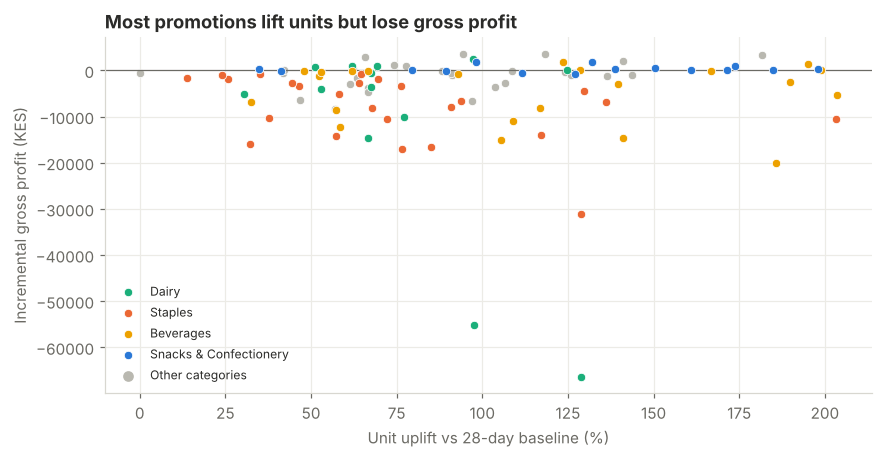

In [10]:
p = an.sql_output("q18_promotion_performance")
s = an.sql_output("q19_promotion_summary_by_category")
fig, ax = plt.subplots(figsize=(9, 4.2))
cats = s.category.tolist()
pal = {c: col for c, col in zip(["Snacks & Confectionery", "Staples", "Dairy", "Beverages"], [an.PRIMARY, an.HIGHLIGHT, an.SECOND, an.SERIES[3]])}
for c in p.category.unique():
    d = p[p.category == c]
    ax.scatter(d.unit_uplift_pct, d.incremental_gp_kes, s=30, color=pal.get(c, an.CONTEXT), label=c if c in pal else None, edgecolor="white", lw=.5, zorder=3 if c in pal else 2)
ax.scatter([], [], color=an.CONTEXT, label="Other categories")
ax.axhline(0, color=an.INK_MUTED, lw=.8); ax.set_xlabel("Unit uplift vs 28-day baseline (%)"); ax.set_ylabel("Incremental gross profit (KES)")
ax.set_title("Most promotions lift units but lose gross profit"); ax.legend(fontsize=8, loc="lower left")
an.save(fig, "promotion_uplift_vs_gp");
print(p.outcome.value_counts().to_string()); s

A promotion pays back only when the extra units' margin exceeds the margin given away on units that would have sold anyway. With a 10% margin, a 15% discount on cooking oil makes *every* unit loss-making, so no level of uplift can recover it. **Snacks & Confectionery** is the only category with a positive net return (high uplift, healthy margin), and Personal Care roughly breaks even. Staples and Dairy promotions destroy the most gross profit.

Caveats: chain-level 28-day baseline; cannibalisation, pantry loading and footfall effects are not measured. Treat this as a screening result to test with controlled promotions, not a final causal estimate.